**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Samuel Enrique Garza Montemayor 
*   MATRÍCULA: A00829926

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [98]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer
from IPython.display import display
pd.set_option('display.max_colwidth', None)

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [7]:
cardio_df = pd.read_csv('heart_disease.csv')

In [8]:
cardio_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        918 non-null    int64  
 1   age       918 non-null    int64  
 2   sex       918 non-null    str    
 3   origin    918 non-null    str    
 4   cp        918 non-null    str    
 5   trestbps  859 non-null    float64
 6   chol      888 non-null    float64
 7   fbs       829 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    863 non-null    float64
 10  exang     863 non-null    object 
 11  oldpeak   856 non-null    float64
 12  slope     610 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       918 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 114.9+ KB


Tipos de variables en cardio_df: 

* 8 Variables Numéricas 
* 8 Variables de Texto 

In [9]:
cardio_df.nunique()

id          918
age          50
sex           2
origin        4
cp            4
trestbps     60
chol        216
fbs           2
restecg       3
thalch      119
exang         2
oldpeak      53
slope         3
ca            4
thal          3
num           5
dtype: int64

Aqui vemos que solo la variable "id" es la única que tiene todos sus valores únicos, y eso es normal por que es un identificador

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [33]:
posibles_categoricas = cardio_df.select_dtypes(include='number').nunique()[lambda x: x < 8]
posibles_categoricas

ca     4
num    5
dtype: int64

In [39]:
cardio_df.ca.value_counts()

ca
0    181
1     67
2     41
3     20
Name: count, dtype: int64

In [40]:
cardio_df.num.value_counts()

num
0    411
1    263
2    109
3    107
4     28
Name: count, dtype: int64

In [41]:
cardio_df[posibles_categoricas.index] = cardio_df[posibles_categoricas.index].astype('category')

Las variables de ca (número de vasos coloreados por fluoroscopía), y nuestra variable label 'num' son categóricas y a continuación se codificaran como números

La variable 'ca' es una variable que indica el número de vasos sanguíneos principales, y toma valores del 0 al 3. al ser un conteo (1 vaso, 2 vasos, etc), tiene un orden de menor a mayor tipo ordinal

In [34]:
cardio_df['ca'] = pd.Categorical(cardio_df['ca'],categories=[0, 1, 2, 3],ordered=True)

La variable 'num' (diagnóstico de enfermedad cardíaca) toma valores del 0 al 4. El 0 indica que la persona no tiene enfermedad, mientras que del 1 al 4 indican que tan grave es la enfermedad, por lo tanto tambien es una variable ordinal

In [35]:
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [ ]:
# descriptivos de variables numéricas

num_cols = cardio_df.drop(columns = 'id').select_dtypes(include='number')
stats_numericas = num_cols.describe()
stats_numericas.loc['sesgo'] = num_cols.skew()
stats_numericas.loc['curtosis'] = num_cols.kurt()
display(stats_numericas)

,age,trestbps,chol,thalch,oldpeak
count,918.000000,859.000000,888.000000,863.000000,856.000000
mean,53.530501,132.294529,242.189189,137.528389,0.880607
std,9.412783,18.535875,53.424806,25.950226,1.091840
min,28.000000,80.000000,85.000000,60.000000,-2.600000
25%,47.000000,120.000000,216.000000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000
75%,60.000000,140.000000,268.000000,157.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000
sesgo,-0.193710,0.630411,1.640672,-0.209319,1.037990
curtosis,-0.382511,0.632992,6.573848,-0.483939,1.119834


In [43]:
cardio_df.ca.value_counts()

ca
0    181
1     67
2     41
3     20
Name: count, dtype: int64

In [51]:
(
    (
    cardio_df
    .select_dtypes(include=['category', 'object', 'bool'])
    .pipe(lambda df_: df_.astype(str).mask(df_.isna()))
    .melt(var_name='Variable', value_name='Categoría')
    .value_counts(dropna=False)
    .to_frame(name='Conteo')
    .reset_index()
    .assign(porc=lambda df_: (df_['Conteo'] / df_.groupby('Variable')['Conteo'].transform('sum')))
    .set_index(['Variable', 'Categoría'])
    .sort_index()
)
)

/var/folders/t8/14dhnm257w59pvg7ptny4cgc0000gn/T/ipykernel_11831/4212908834.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(include=['category', 'object', 'bool'])


Conteo      porc
Variable Categoría                          
ca       0.0                   181  0.197168
         1.0                    67  0.072985
         2.0                    41  0.044662
         3.0                    20  0.021786
         nan                   609  0.663399
cp       asymptomatic          495  0.539216
         atypical angina       174  0.189542
         non-anginal           204  0.222222
         typical angina         45  0.049020
exang    False                 526  0.572985
         True                  337  0.367102
         nan                    55  0.059913
fbs      False                 691  0.752723
         True                  138  0.150327
         nan                    89  0.096950
num      0                     411  0.447712
         1                     263  0.286492
         2                     109  0.118736
         3                     107  0.116558
         4                      28  0.030501
origin   Cleveland             304  0.331155
         Hungary               292  0.318083
         Switzerland           122  0.132898
         VA Long Beach         200  0.217865
restecg  lv hypertrophy        188  0.204793
         normal                551  0.600218
         st-t abnormality      179  0.194989
sex      Female                194  0.211329
         Male                  724  0.788671
slope    downsloping            63  0.068627
         flat                  345  0.375817
         upsloping             202  0.220044
         nan                   308  0.335512
thal     fixed defect           46  0.050109
         normal                196  0.213508
         reversable defect     192  0.209150
         nan                   484  0.527233

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [ ]:
cardio_df.isna().mean()*100

id           0.000000
age          0.000000
sex          0.000000
origin       0.000000
cp           0.000000
trestbps     6.427015
chol         3.267974
fbs          9.694989
restecg      0.000000
thalch       5.991285
exang        5.991285
oldpeak      6.753813
slope       33.551198
ca          66.339869
thal        52.723312
num          0.000000
dtype: float64

Se eliminaran las columnas con >30% de Nulos ('slope', 'ca', y 'thal')

In [61]:
porcentaje_nulos = cardio_df.isna().mean()
columnas_menor_30_nans = porcentaje_nulos[porcentaje_nulos <= 0.30].index

In [63]:
cardio_df = cardio_df[columnas_menor_30_nans]
cardio_df

,id,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,1
914,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,0
915,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,2
916,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,0


Se han eliminado las columnas con >30% de Nulos

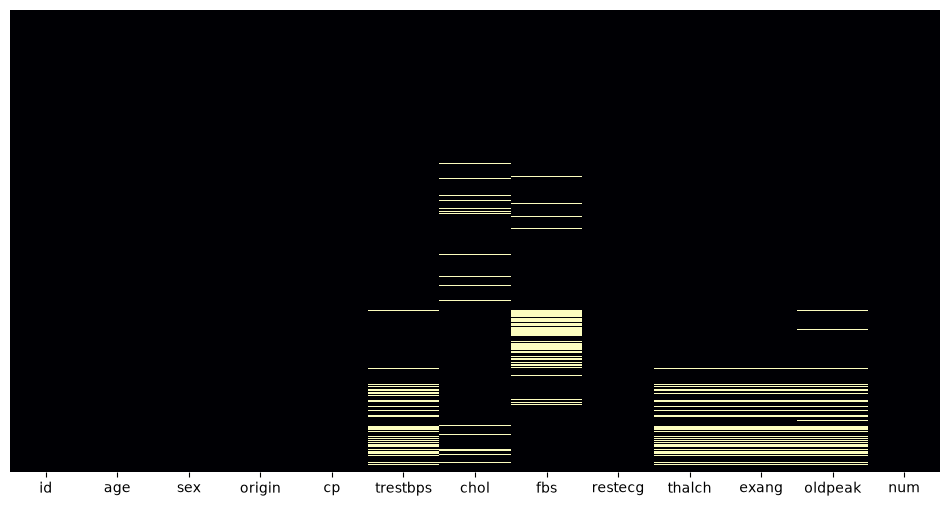

In [69]:
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='magma', yticklabels=False)
plt.show()

Por lo que podemos observar en el mapa de calor las variables que tienen valores nulos de manera simultanea se encuentean en la paerte inferior derecha del mapa y son:
* thalch: frecuencia cardíaca máxima alcanzada
* exang: angina inducida por el ejercicio
* oldpeak: depresión del segmento ST inducida por el ejercicio en relación con el reposo

Parece ser que estas variables son output de una prueba de esfuerzo. Parece ser que algunos pasientes tuvieron complicaciones al hacer la prueba por lo que resulta imposible registrar estas métricas simultáneamente, y es por eso que todas aparecen como Nulo. 



5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [75]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series(dtype=object, index=BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [71]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

In [ ]:
from scipy.stats import ttest_ind, chi2_contingency


--- ANÁLISIS NUMÉRICO: age ---


/var/folders/t8/14dhnm257w59pvg7ptny4cgc0000gn/T/ipykernel_11831/266015007.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(box_sr,vert=False)


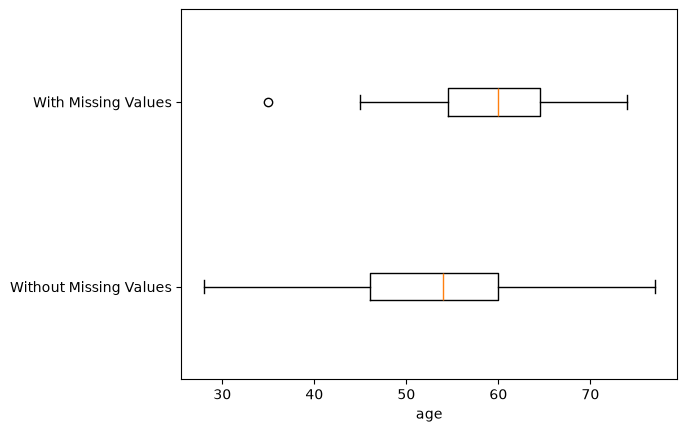

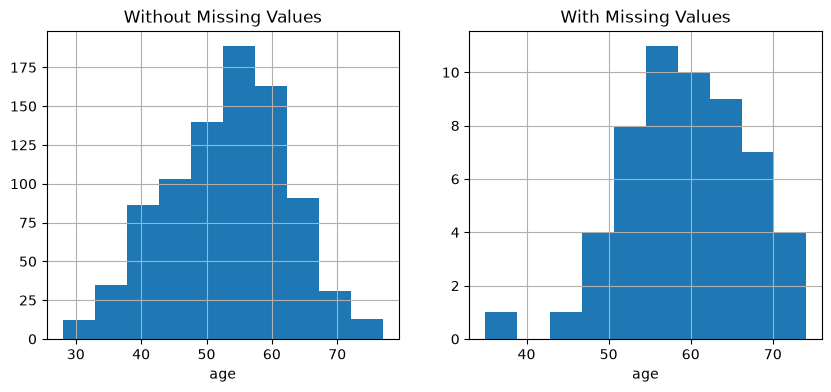

p-value of t-test: 1.5041244185890923e-06

--- ANÁLISIS NUMÉRICO: chol ---


/var/folders/t8/14dhnm257w59pvg7ptny4cgc0000gn/T/ipykernel_11831/266015007.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(box_sr,vert=False)


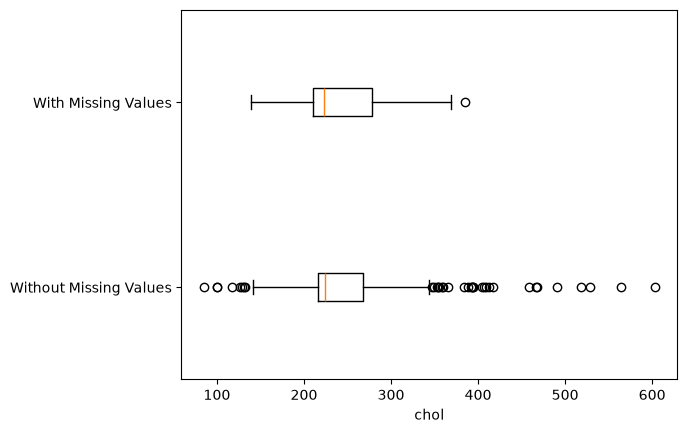

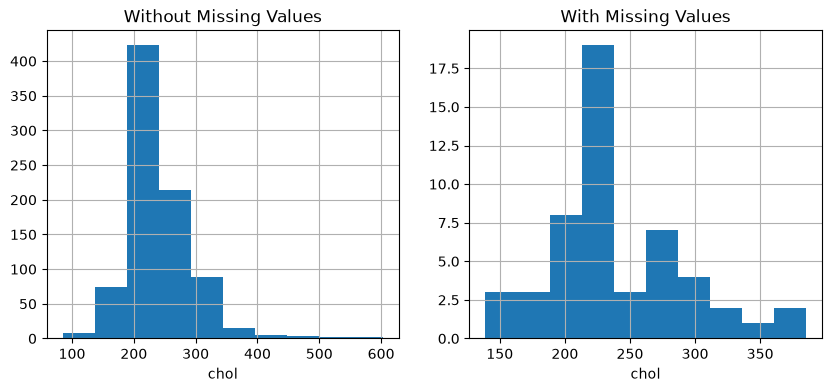

p-value of t-test: 0.7165289974295671

--- ANÁLISIS CATEGÓRICO: restecg ---


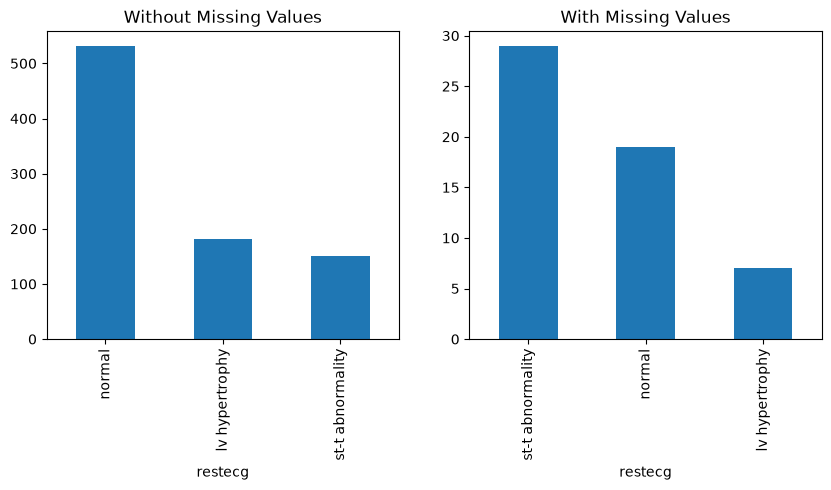

p-value of Chi_squared test: 1.1472889573985467e-09

--- ANÁLISIS CATEGÓRICO: cp ---


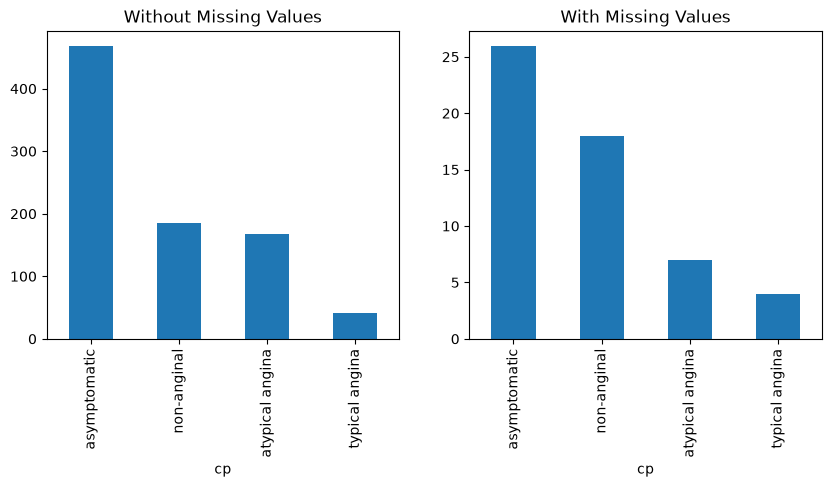

p-value of Chi_squared test: 0.1542009717725172


In [77]:
BM_MV = cardio_df['thalch'].isna()

print("--- ANÁLISIS NUMÉRICO: age ---")
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV)

print("\n--- ANÁLISIS NUMÉRICO: chol ---")
Diagnose_MV_Numerical(cardio_df, 'chol', BM_MV)

print("\n--- ANÁLISIS CATEGÓRICO: restecg ---")
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV)

print("\n--- ANÁLISIS CATEGÓRICO: cp ---")
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV)

Variables que SI influyen los nulos (pvalor< 0.05): 
* Age: Con un pvalor de 1.50e-06 indica que si presenta diferencias estadísticamente significativas, esto lo podemos interpretar como que a los pacientes de alta edad tienen una probabilidad mayor de no contar con el dato de thalch.

* restecg: com un pvalor de 1.147e-09 indica que si presenta diferencias estadísticamente significativas, es decir personas con anomalías cardiacas son mas probables a no contar con el dato de thalch. 

Variables que NO influyen los nulos (pvalor>0.05): 

* chol: el colesterol con un pvalor de 0.71 no muestra significancia estadística. Su distribución es prácticamente igual si lo segmentamos en nulos y no nulos de la variable thalch

* cp: el tipo de dolor de pecho con un pvalor de 0.15 no muestra significancia estadística. Su distribución es prácticamente igual, por lo que no es factoer decisivo para omitir la prueba de esfuerzo (thalch)

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [78]:
cardio_df = (
    cardio_df
    .assign(
        thalch=lambda df_: df_.groupby('restecg')['thalch'].transform(lambda x: x.fillna(x.median())),
        oldpeak=lambda df_: df_.groupby('restecg')['oldpeak'].transform(lambda x: x.fillna(x.median())),
        
        exang=lambda df_: df_.groupby('restecg')['exang'].transform(
            lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x)
        )
    )
)

<Axes: >

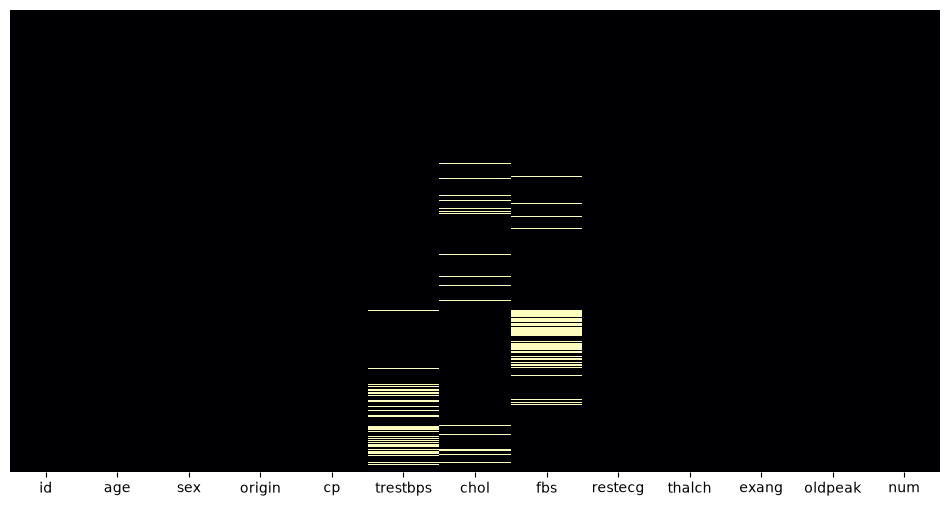

In [82]:
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='magma', yticklabels=False)

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [91]:
from sklearn.impute import SimpleImputer
imputer_median = SimpleImputer(strategy='median')
imputer_mean= SimpleImputer(strategy='mean')
imputer_mode = SimpleImputer(strategy='most_frequent')

In [89]:
cardio_df.trestbps.describe()

count    918.000000
mean     132.147059
std       17.938497
min       80.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64

In [90]:
cardio_df.chol.describe()

count    918.000000
mean     241.562092
std       52.654405
min       85.000000
25%      217.250000
50%      223.000000
75%      266.750000
max      603.000000
Name: chol, dtype: float64

In [ ]:
cardio_df = (
    cardio_df
    .assign(
        trestbps=lambda df_: imputer_mean.fit_transform(df_[['trestbps']])[:, 0],
        chol=lambda df_: imputer_median.fit_transform(df_[['chol']])[:, 0],
        fbs=lambda df_: imputer_mode.fit_transform(df_[['fbs']])[:, 0])
)

In [88]:
cardio_df.trestbps.describe()

count    918.000000
mean     132.147059
std       17.938497
min       80.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64

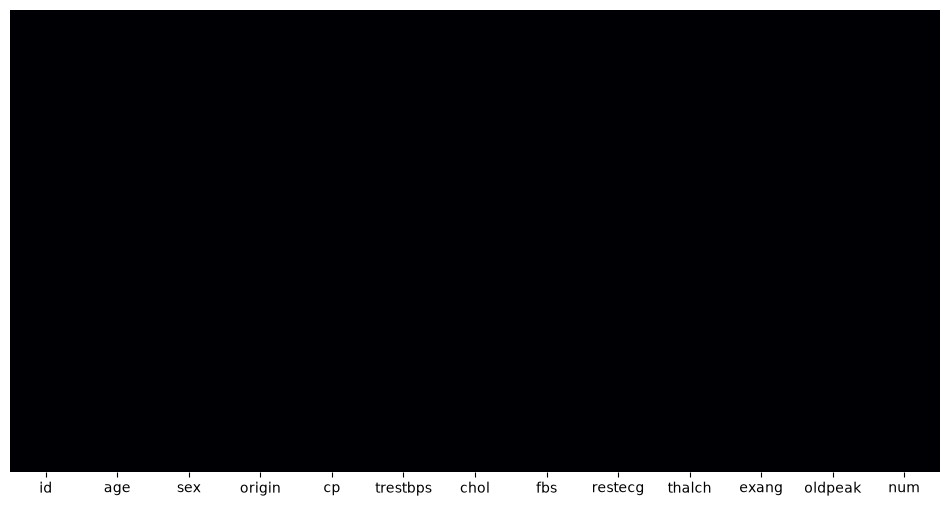

In [87]:
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='magma', yticklabels=False)
plt.show()

Como podemos ver ya no existen valores faltantes en nuestro dataframe, a continuación se justifica el método de imputación: 

* trestbps: Se imputaron los valores nulos con el promedio de la variable, no presenta muchos outliers y el promedio es muy similar a la median (130 y 132)
* chol: Se imputaron los valores nulos con la mediana de la variable, al tener muchos outliers (promedio muy superior a la mediana) podemos sesgar al rellenar datos con un valor inflado que es jalado hacia arriba por los outliers. 

* fbs: para esta variable booleana utilizamos la moda para rellenar los nulos, y es que no podemos usar el promedio o la mediana ya que los únicos valores posibles son 1 y 0



8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

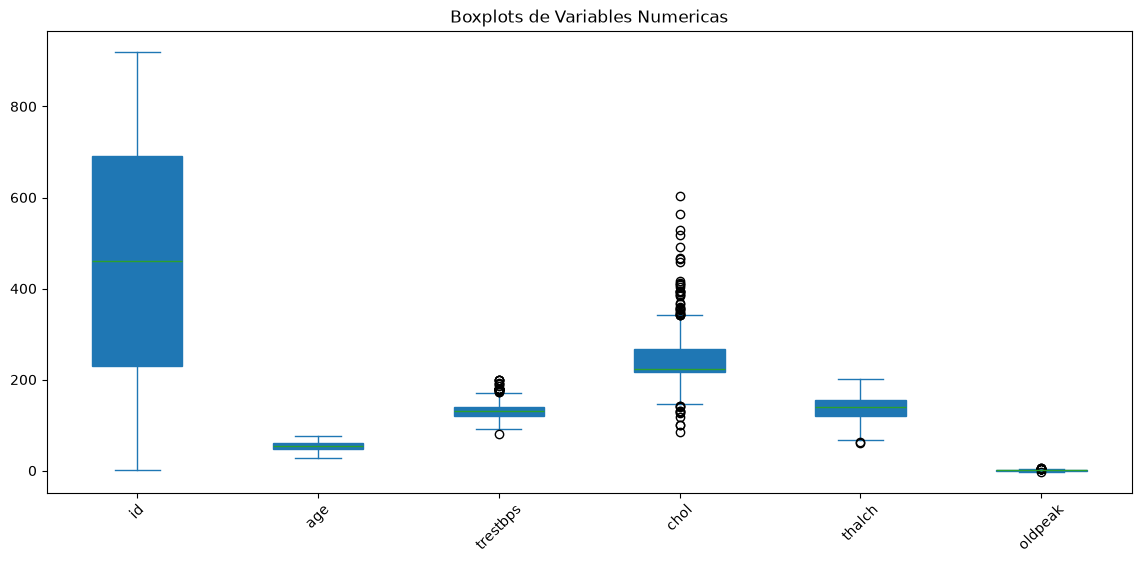

In [105]:
df_num = cardio_df.select_dtypes(include='number')

ax_dict = df_num.plot(
    kind='box', 
    figsize=(14, 6), 
    return_type='dict', 
    patch_artist=True
)
plt.title('Boxplots de Variables Numericas')
plt.xticks(rotation=45)
plt.show()

In [104]:

resumen_atipicos = (
    pd.Series(
        data=map(lambda flier: flier.get_ydata().tolist(), ax_dict['fliers']), 
        index=df_num.columns,
        name='Valores_Atipicos_Crudos'
    )
    .to_frame()
    .assign(
        Cantidad_valores_atipicos =lambda df_: df_['Valores_Atipicos_Crudos'].str.len(),
                
        Valores_Atipicos=lambda df_: df_['Valores_Atipicos_Crudos'].apply(lambda x: x if len(x) > 0 else '---')
    )
    .loc[:, ['Cantidad_valores_atipicos', 'Valores_Atipicos']]
)

display(resumen_atipicos)

,Cantidad_valores_atipicos,Valores_Atipicos
id,0,---
age,0,---
trestbps,27,"[80.0, 172.0, 180.0, 200.0, 174.0, 178.0, 192.0, 180.0, 178.0, 180.0, 190.0, 180.0, 180.0, 180.0, 180.0, 200.0, 180.0, 180.0, 180.0, 200.0, 185.0, 200.0, 180.0, 178.0, 172.0, 180.0, 190.0]"
chol,44,"[141.0, 126.0, 131.0, 132.0, 129.0, 100.0, 85.0, 117.0, 100.0, 142.0, 139.0, 354.0, 353.0, 417.0, 360.0, 407.0, 564.0, 394.0, 409.0, 342.0, 358.0, 412.0, 468.0, 365.0, 344.0, 394.0, 347.0, 466.0, 529.0, 392.0, 355.0, 603.0, 342.0, 404.0, 518.0, 388.0, 491.0, 342.0, 393.0, 458.0, 384.0, 349.0, 369.0, 385.0]"
thalch,2,"[60.0, 63.0]"
oldpeak,16,"[-2.6, 6.2, 4.0, 5.6, 4.0, 4.2, 4.2, 3.8, 4.4, 4.0, 4.0, 5.0, 4.0, 4.0, 4.0, 4.0]"


9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [ ]:
q1 = cardio_df['trestbps'].quantile(0.25)
q3 = cardio_df['trestbps'].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos_trestbps = (
    cardio_df
    .query('trestbps < @limite_inferior or trestbps > @limite_superior')
    ['trestbps'] 
    .tolist()    
)


In [114]:
len(atipicos_trestbps)

27

In [115]:
atipicos_trestbps

[172.0,
 180.0,
 200.0,
 174.0,
 178.0,
 192.0,
 180.0,
 178.0,
 180.0,
 190.0,
 180.0,
 180.0,
 180.0,
 180.0,
 200.0,
 180.0,
 180.0,
 80.0,
 180.0,
 200.0,
 185.0,
 200.0,
 180.0,
 178.0,
 172.0,
 180.0,
 190.0]

Si coinciden los valores atípicos encontrados, son 27 en total para la variable trestbps

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [116]:
cardio_df_clean = (
    cardio_df
    .query('trestbps >= @limite_inferior and trestbps <= @limite_superior')
)

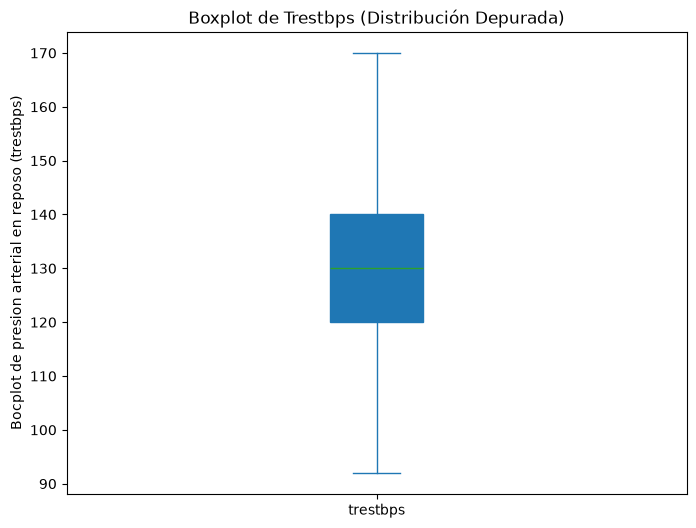

In [118]:
plt.figure(figsize=(8, 6))

(cardio_df_clean['trestbps']
    .plot(
        kind='box', 
        patch_artist=True,
        title='Boxplot de Trestbps (Distribución Depurada)')
)

plt.ylabel('Bocplot de presion arterial en reposo (trestbps)')
plt.show()

---

**Declaración de uso de IA**



*   Google. (2026). *Gemini (basado en Pro 3.1)* [Modelo de lenguaje grande], utilizado para construcción de código y corrección de errores. https://gemini.google.com/
---